In [1]:
import h5py
import pylab as plt
import numpy as np
from matplotlib.dates import num2date
from datetime import datetime
import pytz

# Load Samples Data

In [2]:
hdf_samples = h5py.File('../data/validation/unsignedflux_samples.h5')
print(hdf_samples.keys())
#lat_extent_samples = hdf_samples['lat_extent'][:].squeeze()
unsigned_flux_samples = hdf_samples['unsigned_flux'][:].squeeze()
times_d2n = hdf_samples['times_d2n'][:]
hdf_samples.close()

<KeysViewHDF5 ['contexts', 'rs', 'times_d2n', 'unsigned_flux']>


In [3]:
unsigned_flux_samples.shape

(835, 4)

In [4]:
times_samples = np.array(num2date(times_d2n))

In [5]:
unsigned_flux_samples

array([[108576.19975514,   2062.53254717,   1035.78267606,
           743.25726713],
       [109969.42385586,   1922.71831856,    928.75396266,
           621.24402173],
       [148021.01199491,   3052.94960182,   1467.59239759,
           999.13179823],
       ...,
       [182340.62401313,   4562.60118176,   2106.81313924,
          1399.52081695],
       [214584.86221039,   4518.09903145,   2055.86253245,
          1360.13327331],
       [201876.11451569,   4670.29247429,   1999.31219318,
          1216.06289613]], shape=(835, 4))

# Load Training Data

In [6]:
hdf_testdata = h5py.File('../data/validation/unsignedflux_testdata.h5')
unsigned_flux_testdata = hdf_testdata['unsigned_flux'][:].squeeze()
hdf_testdata.close()

In [7]:
unsigned_flux_testdata.shape

(835, 4)

In [8]:
unsigned_flux_testdata

array([[157078.13428143,   2224.45728304,   1313.85903738,
          1007.12179276],
       [124517.81193924,   2002.39891689,   1211.97437464,
           953.07704312],
       [174747.41673807,   2284.20190364,   1234.33329262,
           906.05566932],
       ...,
       [118091.5118146 ,   2169.16437101,   1431.27044653,
          1151.4307471 ],
       [118091.5118146 ,   2169.16437101,   1431.27044653,
          1151.4307471 ],
       [118091.5118146 ,   2169.16437101,   1431.27044653,
          1151.4307471 ]], shape=(835, 4))

# Plot Experiment

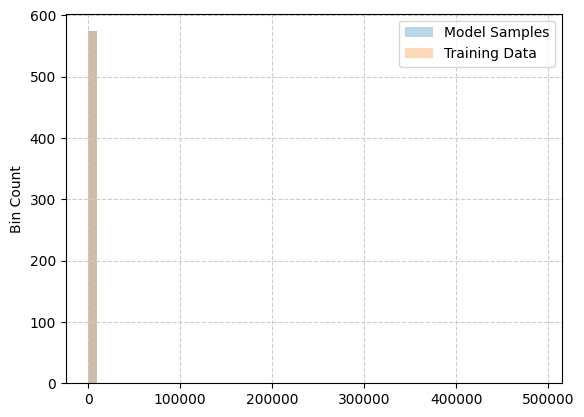

In [15]:
#bins = np.arange(0, 50000, 1000)

bins = [
    np.arange(0, 500_000, 10000),  
    np.arange(0, 500_000, 10000), 
    np.arange(0, 500_000, 10000), 
    np.arange(0, 500_000, 10000), 

]
cutoff = datetime(2021, 1, 1).replace(tzinfo=pytz.utc)  
mask = times_samples < cutoff

plt.hist(unsigned_flux_samples[mask, 2], label='Model Samples', bins=bins, alpha=0.3)
plt.hist(unsigned_flux_testdata[mask, 2], bins=bins,  label='Training Data', alpha=0.3)

plt.legend()
plt.ylabel('Bin Count')
#plt.xlabel(r'Latitudinal Extent of Current Sheet at 2.5 $R_\odot$ (deg)')
#plt.title('Histograms of Latitudinal Extent of Current Sheet at 2.5 $R_\odot$')
#plt.xlim(0, 180)
plt.grid(linestyle='dashed', color='#ccc')
#plt.savefig('../plots/paper/csextent.png', dpi=300)

In [10]:
for i in range(4):
    print(np.mean(unsigned_flux_testdata[mask, i])  /  np.mean(unsigned_flux_samples[mask, i]) )

1.3266709652999218
1.0250740011318207
1.00384788396792
1.000080064580862


In [11]:
 1/ (np.pi * 4 * np.sqrt(2))

np.float64(0.05626976975981913)

In [12]:
print('Samples')
print('---------')
print('Mean', np.mean(unsigned_flux_samples[times_samples < cutoff]))
print('STD', np.std(unsigned_flux_samples[times_samples < cutoff]))
print()
print('Training Data')
print('---------')
print('Mean', np.mean(unsigned_flux_testdata[times_samples < cutoff]))
print('STD', np.std(unsigned_flux_testdata[times_samples < cutoff]))
print()

Samples
---------
Mean 47352.13504928532
STD 87448.52106982449

Training Data
---------
Mean 62298.42672216508
STD 119534.40562192579

